In [12]:
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
sns.set_theme(style="whitegrid")

In [13]:
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

def find_file(zf, name):

    for n in zf.namelist():
        if n.endswith(name):
            return zf.read(n)
        if n.endswith(".zip"):
            inner = zipfile.ZipFile(io.BytesIO(zf.read(n)))
            found = find_file(inner, name)
            if found is not None:
                return found
    return None

raw = urllib.request.urlopen(url).read()
content = find_file(zipfile.ZipFile(io.BytesIO(raw)), "student-mat.csv")
df = pd.read_csv(io.BytesIO(content), sep=";")

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [14]:
print("Shape:", df.shape)
print("Missing values (total):", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()

Shape: (395, 33)
Missing values (total): 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    o

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


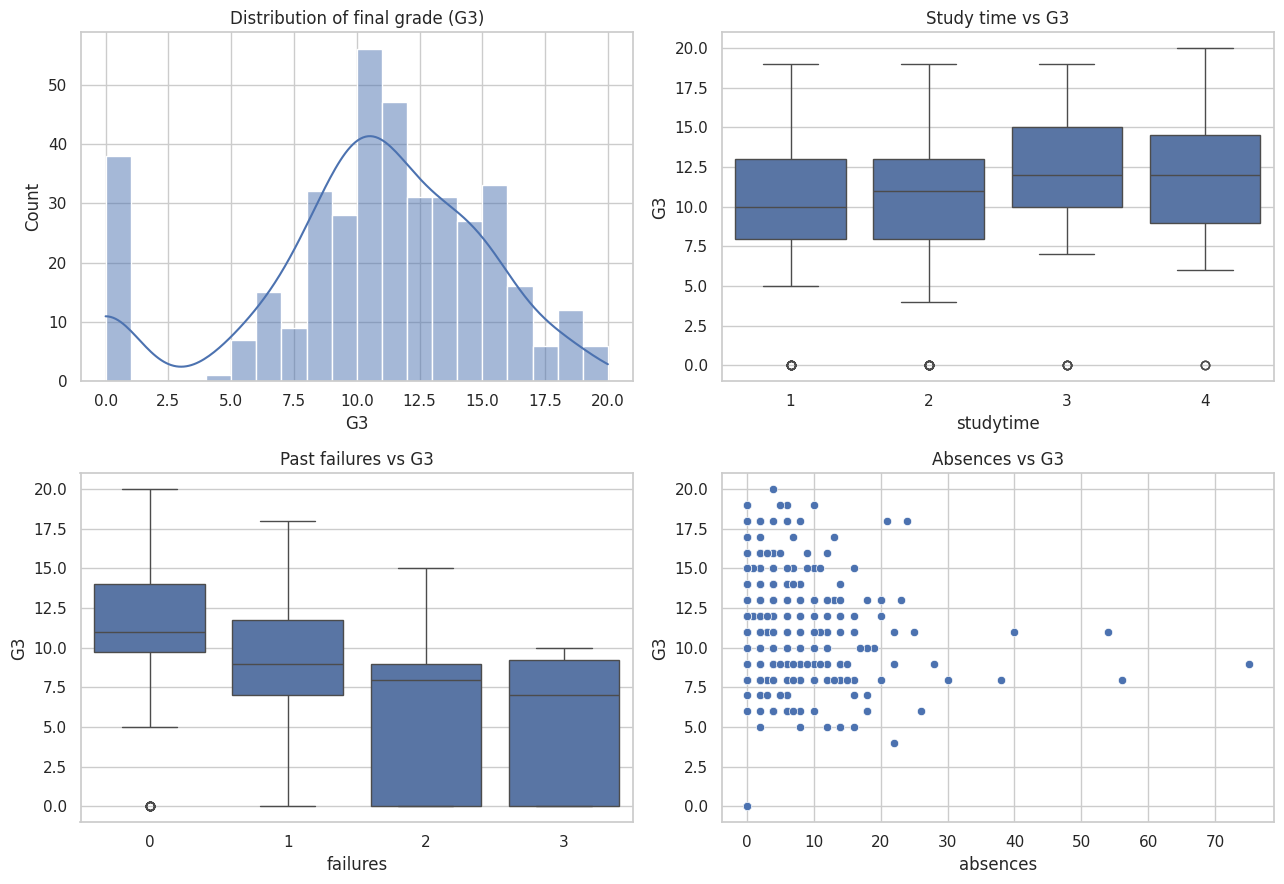

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df["G3"], bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of final grade (G3)")

sns.boxplot(x="studytime", y="G3", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Study time vs G3")

sns.boxplot(x="failures", y="G3", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Past failures vs G3")

sns.scatterplot(x="absences", y="G3", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Absences vs G3")

plt.tight_layout()
plt.show()

In [20]:
def run_experiment(df, drop_cols=()):
    X = df.drop(columns=["G3"] + list(drop_cols))
    y = df["G3"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    cat_cols = X.select_dtypes(include="object").columns.tolist()
    num_cols = X.select_dtypes(exclude="object").columns.tolist()

    preprocess = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

    models = {
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Ridge(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
        "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    }

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    rows, fitted = [], {}

    for name, model in models.items():
        pipe = Pipeline([("prep", preprocess), ("model", model)])

        cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2").mean()

        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)

        rows.append({
            "Model": name,
            "CV R2": round(cv_r2, 3),
            "Test MAE": round(mean_absolute_error(y_test, pred), 3),
            "Test RMSE": round(np.sqrt(mean_squared_error(y_test, pred)), 3),
            "Test R2": round(r2_score(y_test, pred), 3),
        })
        fitted[name] = pipe

    results = pd.DataFrame(rows).set_index("Model")
    return results, fitted, X_test, y_test

In [21]:
results_all, fitted_all, Xte_all, yte_all = run_experiment(df)
print("Scenario A - with G1 and G2")
results_all

Scenario A - with G1 and G2


,CV R2,Test MAE,Test RMSE,Test R2
Model,,,,
Linear Regression,0.804,1.647,2.378,0.724
Ridge Regression,0.806,1.639,2.372,0.726
Random Forest,0.890,1.201,2.015,0.802
Gradient Boosting,0.876,1.153,1.983,0.808


In [22]:
results_no, fitted_no, Xte_no, yte_no = run_experiment(df, drop_cols=["G1", "G2"])
print("Scenario B - without G1 and G2")
results_no

Scenario B - without G1 and G2


,CV R2,Test MAE,Test RMSE,Test R2
Model,,,,
Linear Regression,-0.092,3.395,4.196,0.141
Ridge Regression,-0.080,3.393,4.193,0.142
Random Forest,0.201,2.994,3.751,0.314
Gradient Boosting,0.158,3.111,3.936,0.244


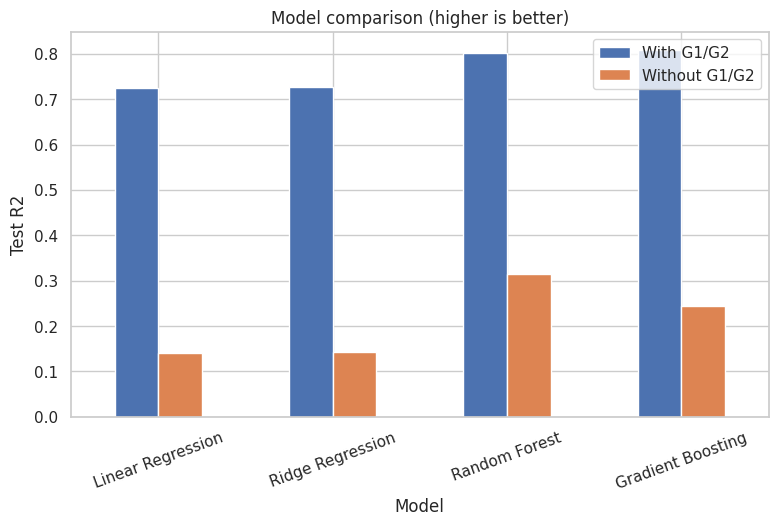

In [23]:
comparison = pd.DataFrame({
    "With G1/G2": results_all["Test R2"],
    "Without G1/G2": results_no["Test R2"],
})
comparison.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Test R2")
plt.title("Model comparison (higher is better)")
plt.xticks(rotation=20)
plt.show()

Best model without G1/G2: Random Forest


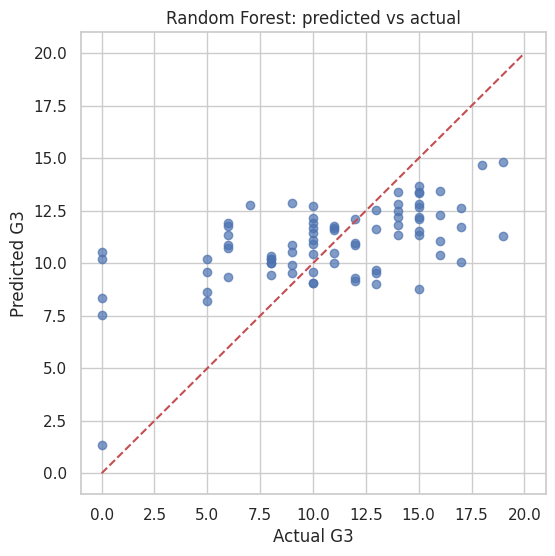

In [24]:
best_name = results_no["Test R2"].idxmax()
print("Best model without G1/G2:", best_name)

pred = fitted_no[best_name].predict(Xte_no)
plt.figure(figsize=(6, 6))
plt.scatter(yte_no, pred, alpha=0.7)
plt.plot([0, 20], [0, 20], "r--")
plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.title(f"{best_name}: predicted vs actual")
plt.show()

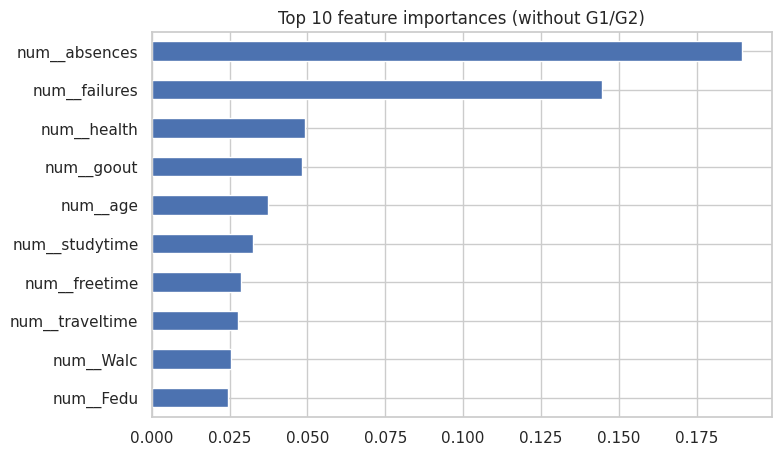

In [25]:
rf_pipe = fitted_no["Random Forest"]
names = rf_pipe.named_steps["prep"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_

imp = pd.Series(importances, index=names).sort_values(ascending=False).head(10)
imp.iloc[::-1].plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 feature importances (without G1/G2)")
plt.show()